# The landau logo

Both versions of the logo are phase diagrams that landau computes and draws itself:

- **Lens**: a solid and a liquid ideal solution, with the two-phase lens between them.
- **Compound**: a congruently melting line compound between two eutectics.

`calc_phase_diagram` locates the fields, `plot_phase_diagram` draws them, and the rest of this notebook only
restyles what it drew: colours, outline widths, stacking order and a rounded frame. As in every landau diagram,
the two-phase regions are left white.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch

from landau import IdealSolution, LinePhase, plot_phase_diagram
from landau.calculate import calc_phase_diagram
from landau.phases import S, kB

%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
plt.rcParams["figure.dpi"] = 100

## Palette

Ink for lines and text, violet for the liquid, amber for the solid. Both colours sit at a middle lightness so the
mark reads on light and dark backgrounds alike. The wordmark is set in IBM Plex Mono (SemiBold); matplotlib falls
back to DejaVu Sans Mono where it is not installed.

In [2]:
INK = "#1C1B33"
PAPER = "#FFFFFF"
LIQUID = "#8E7CFF"
SOLID = "#F29E4C"

COLORS = {"liquid": LIQUID, "solid": SOLID, "AB": SOLID, "A": PAPER, "B": PAPER}
PLEX = any(f.name == "IBM Plex Mono" for f in font_manager.fontManager.ttflist)
WORDMARK = {"family": "IBM Plex Mono" if PLEX else "DejaVu Sans Mono", "weight": 600 if PLEX else 700}

## Phases

Every free energy is measured from the pure liquids, so `crystal(name, c, T_m, dS)` is a line phase that melts at
`T_m` with an entropy of fusion of `dS` (in units of $k_B$).

In [3]:
def crystal(name, c, T_m, dS):
    return LinePhase(name, fixed_concentration=c, line_energy=-dS * kB * T_m, line_entropy=-dS * kB)


liquid = IdealSolution(
    "liquid",
    LinePhase("A(l)", fixed_concentration=0, line_energy=0.0, line_entropy=0.0),
    LinePhase("B(l)", fixed_concentration=1, line_energy=0.0, line_entropy=0.0),
)

### Lens

A solid ideal solution of two crystals melting at 800 K and 1600 K. An entropy of fusion of $4\,k_B$ on both sides
opens the lens wide enough to stay visible at small sizes.

In [4]:
solid = IdealSolution("solid", crystal("A", 0, 800, 4.0), crystal("B", 1, 1600, 4.0))
lens = calc_phase_diagram([solid, liquid], Ts=np.linspace(300, 2000, 100), mu=200)

### Compound

Pure A melts at 1250 K and pure B at 1500 K. The compound AB at $c = 0.45$ is given the energy that makes it melt
congruently at 1300 K, i.e. $f_\mathrm{AB}(T_C) = -T_C\,S(c)$, the free energy of the ideal liquid at its
composition. Small entropies of fusion for AB and B make a sharp dome and push the right eutectic below the left.

In [5]:
T_C, dS_C, c_C = 1300, 0.4, 0.45
compound = LinePhase(
    "AB", fixed_concentration=c_C, line_energy=-T_C * dS_C * kB - T_C * S(c_C), line_entropy=-dS_C * kB
)
eutectics = calc_phase_diagram(
    [liquid, crystal("A", 0, 1250, 1.5), compound, crystal("B", 1, 1500, 0.4)],
    Ts=np.linspace(700, 1650, 100),
    mu=200,
)

Drawn with landau's defaults, these are ordinary phase diagrams:

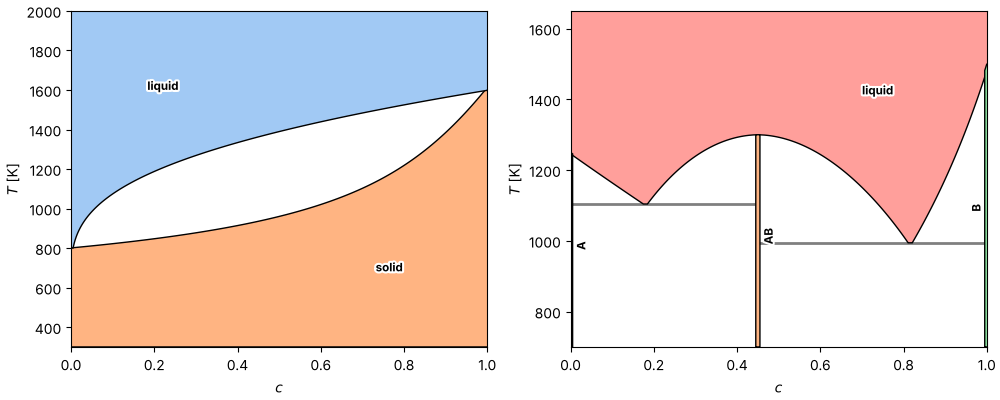

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
plot_phase_diagram(lens, ax=axes[0])
plot_phase_diagram(eutectics, ax=axes[1], triplepoints=True);

## The mark

`draw_mark` lets `plot_phase_diagram` draw the diagram into `ax` and then restyles its artists:

- Widths are measured in 1/88 of the frame's width, so the mark scales as a whole.
- The stacking order runs from the eutectic isotherms (deepest), through the line compound, to the phase fields.
- The line compound gets an outline in its own colour, which widens it into a bar.
- The terminal line phases of the compound diagram coincide with the frame and are hidden.
- Everything is clipped to a rounded square of white paper, and the frame is drawn on top.

`outlines` and `isotherms` switch the ink lines inside the frame off, which small sizes need.

In [7]:
ROUND = 14 / 88  # corner radius, as a fraction of the frame's width
ROLES = {"liquid": "field", "solid": "field", "AB": "bar", "A": "hide", "B": "hide"}


def draw_mark(ax, df, *, outlines=True, isotherms=True, frame=INK, frame_width=5):
    with warnings.catch_warnings():
        # the hidden terminal line phases are degenerate polygons
        warnings.simplefilter("ignore", UserWarning)
        plot_phase_diagram(df, ax=ax, legend=False, triplepoints=isotherms, color_override=COLORS)
    ax.set_axis_off()
    ax.set_xlim(0, 1)

    unit = ax.get_position().width * ax.figure.get_figwidth() * 72 / 88  # points
    box = {"boxstyle": f"round,pad=0,rounding_size={ROUND}", "transform": ax.transAxes}
    paper = FancyBboxPatch((0, 0), 1, 1, facecolor=PAPER, edgecolor="none", zorder=0, **box)

    for p in ax.patches:
        role = ROLES[p.get_label().rstrip("'")]
        if role == "field":
            p.set_zorder(3)
            p.set_edgecolor(INK if outlines else "none")
            p.set_linewidth(3.5 * unit)
        elif role == "bar":
            p.set_zorder(2)
            p.set_edgecolor(p.get_facecolor())
            p.set_linewidth(5 * unit)
        else:
            p.set_visible(False)
    for c in ax.collections:  # the isotherms drawn by triplepoints=True
        c.set_color(INK)
        c.set_alpha(1)
        c.set_linewidth(3.5 * unit)
        c.set_zorder(1)

    ax.add_patch(paper)
    for artist in ax.patches + ax.collections:
        if artist is not paper:
            artist.set_clip_path(paper)
    ax.add_patch(FancyBboxPatch((0, 0), 1, 1, facecolor="none", edgecolor=frame,
                                linewidth=frame_width * unit, zorder=10, clip_on=False, **box))


def mark_axes(fig, x, y, size):
    """Axes for a mark of `size` inches at (x, y) inches, leaving room for the frame."""
    W, H = fig.get_size_inches()
    m = 0.06 * size
    return fig.add_axes([(x + m) / W, (y + m) / H, (size - 2 * m) / W, (size - 2 * m) / H])

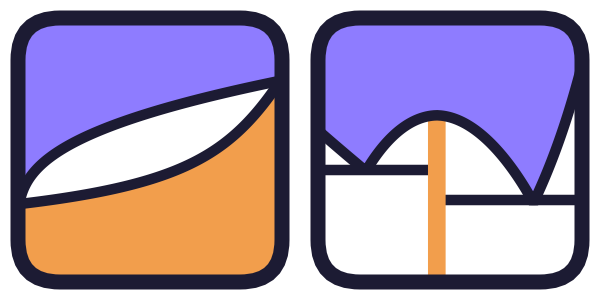

In [8]:
fig = plt.figure(figsize=(6, 3))
draw_mark(mark_axes(fig, 0, 0, 3), lens)
draw_mark(mark_axes(fig, 3, 0, 3), eutectics)

## Wordmark

The lockup puts the mark next to the name, with the text 0.7 times the mark's height. On a dark background the
frame turns white; the paper inside stays white, as it is in every landau plot.

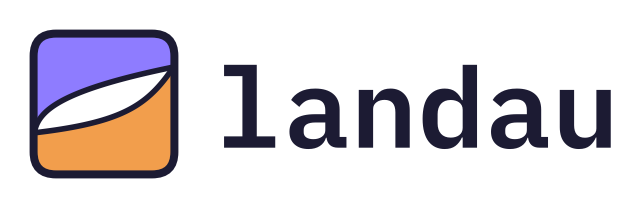

In [9]:
def lockup(df, height=1.6, dark=False):
    fs = 0.7 * height * 72
    width = height * 1.5 + 0.6 * 6 * fs / 72  # Plex Mono advances 0.6 em per letter
    fig = plt.figure(figsize=(width, height * 1.3), facecolor=INK if dark else PAPER)
    draw_mark(mark_axes(fig, 0.15 * height, 0.15 * height, height), df, frame=PAPER if dark else INK)
    fig.text(1.35 * height / width, 0.5, "landau", fontsize=fs, fontdict=WORDMARK,
             color=PAPER if dark else INK, va="center_baseline", ha="left")
    return fig


lockup(lens);

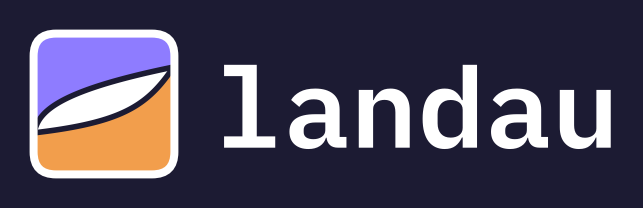

In [10]:
lockup(lens, dark=True);

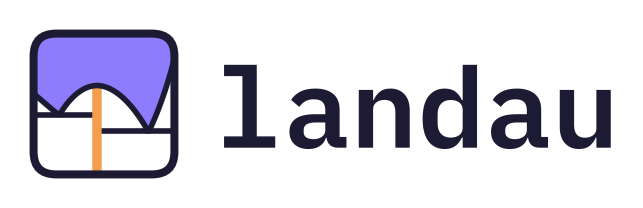

In [11]:
lockup(eutectics);

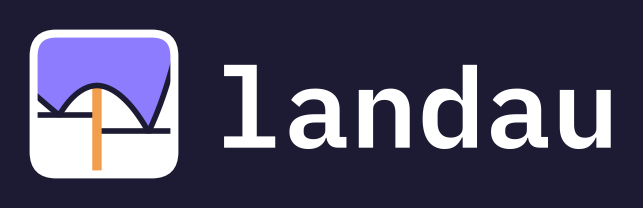

In [12]:
lockup(eutectics, dark=True);

## Small sizes

Thin lines vanish first as the mark shrinks, so the outlines of the phase fields go at 64 px and the isotherms at 32 px,
while the frame grows relative to the mark. Each mark below is drawn at its nominal pixel size.

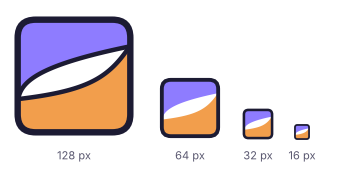

In [13]:
SIZES = [  # pixels, outlines, isotherms, frame width
    (128, True, True, 5),
    (64, False, True, 6),
    (32, False, False, 8),
    (16, False, False, 11),
]


def size_strip(df):
    dpi = plt.rcParams["figure.dpi"]
    fig = plt.figure(figsize=(360 / dpi, 170 / dpi))
    x = 10
    for px, outlines, isotherms, frame_width in SIZES:
        ax = mark_axes(fig, x / dpi, 30 / dpi, px / dpi)
        draw_mark(ax, df, outlines=outlines, isotherms=isotherms, frame_width=frame_width)
        fig.text((x + px / 2) / 360, 8 / 170, f"{px} px", ha="center", va="bottom", fontsize=8, color="#5A5870")
        x += px + 20
    return fig


size_strip(lens);

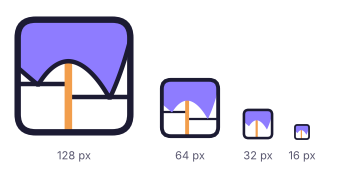

In [14]:
size_strip(eutectics);

Any of these figures can be written out with `fig.savefig(...)`; save as SVG for a vector logo.